# Lab 6 — Convolutional Neural Networks

**This lab is for you. Preparing for the exam starts here.**

Work in pairs. For each investigation: **PREDICT → RUN & OBSERVE → EXPLAIN → EXPERIMENT**. Write your predictions before running the relevant cells. All code is provided; your task is to understand and investigate it.

We will classify handwritten digits using a simple CNN, a modern LeNet-5-inspired CNN, and a fully connected neural network. We also compare a linear classifier.

Complete Investigations 1–6 and final evaluation. If training takes time, discuss the architecture and the training loop with your partner while it runs. Do not tune models using test results.

## Setup
The next cell imports PyTorch and torchvision, sets the batch size, learning rate, epoch budget and device. Run it before proceeding.

NOTE: If Google Colab tells you that no GPU accelerators are currently available, do not worry. You can still run the notebook using the CPU.
Go to Runtime → Change runtime type → CPU, reconnect to the runtime, and run the notebook from the beginning.
You do not need to modify the code: the notebook automatically detects whether a GPU is available and selects the appropriate device.
Please note that training the neural networks on a CPU may take longer.

GPU availability on the free version of Google Colab is not guaranteed and may vary over time.

In [3]:
# Load in relevant libraries, and alias where appropriate
import numpy as np
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms

# Define relevant variables for the ML task
batch_size = 64
num_classes = 10
learning_rate = 0.001

# Device will determine whether to run the training on GPU or CPU.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

SEED = 2223755
torch.manual_seed(SEED)
print("Device:", device)
if device.type == "cuda":
    print(torch.cuda.get_device_name(0))

max_epochs = 25  # Common training budget for all four models


Device: cuda
NVIDIA L4


## Investigation 1 — From images to tensors

MNIST contains grayscale images of handwritten digits (classes 0–9). Original images are 28 × 28 pixels. We resize them to 32 × 32 for the architectures used here. `ToTensor` converts an image to a floating-point tensor with channel-first layout and pixel values in [0,1].

We reserve 10,000 of the original 60,000 training images for validation; the official 10,000 test images remain separate. We estimate a single pixel mean and standard deviation using only the 50,000 training images **after resizing**, then apply the same transformation to all three subsets. This avoids leakage and uses consistent units. DataLoaders group examples into mini-batches of 64; only training batches are shuffled.

**PREDICT:** What are the dimensions of one image tensor and of a batch of 64 images?

In [4]:
base_transform = transforms.Compose([transforms.Resize((32, 32)), transforms.ToTensor()])
full_train = torchvision.datasets.MNIST('./data', train=True, transform=base_transform, download=True)
train_dataset, val_dataset = torch.utils.data.random_split(full_train, [50000, 10000], generator=torch.Generator().manual_seed(1))
# Estimate pixel statistics on the training subset only.
sum_x = sum_x2 = count = 0
for images, _ in torch.utils.data.DataLoader(train_dataset, batch_size=512):
    images = images.double()
    sum_x += images.sum().item()
    sum_x2 += images.square().sum().item()
    count += images.numel()
mean = sum_x / count
std = (sum_x2 / count - mean**2)**0.5
transform = transforms.Compose([transforms.Resize((32, 32)), transforms.ToTensor(), transforms.Normalize((mean,), (std,))])
full_train.transform = transform
test_dataset = torchvision.datasets.MNIST('./data', train=False, transform=transform, download=True)
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True, generator=torch.Generator().manual_seed(SEED))
validation_loader = torch.utils.data.DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
print('Training pixel mean/std before normalization:', mean, std)
print('Split sizes:', len(train_dataset), len(val_dataset), len(test_dataset))
print('Image shape:', train_dataset[0][0].shape)
print('Batch shape:', next(iter(train_loader))[0].shape)

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.58MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 131kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.25MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.11MB/s]


Training pixel mean/std before normalization: 0.1309740019720663 0.2893691436133243
Split sizes: 50000 10000 10000
Image shape: torch.Size([1, 32, 32])
Batch shape: torch.Size([64, 1, 32, 32])


### From images to tensors: image representation and batches

A digital image is represented numerically by its pixel intensities. In PyTorch, a grayscale image of size $32 \times 32$ is represented as a tensor of shape $(1,32,32)$, where the first dimension is the number of channels.

A **batch** is a collection of images processed together. For example, a batch of 64 grayscale images is represented as a four-dimensional tensor of shape $(64,1,32,32)$, following the convention $(N,C,H,W)$: batch size, channels, height, and width.

Unlike a fully connected network, which typically requires each image to be flattened into a vector of 1024 components, a CNN preserves the spatial structure of the image during convolution and pooling.

During training, the images in a mini-batch are processed together, their losses are aggregated, and the resulting gradient is used to perform one parameter update.

The following cell displays one training image and its label. Indexing `[100]` selects the image from the (image, label) pair; the next `[0]` selects its only channel.

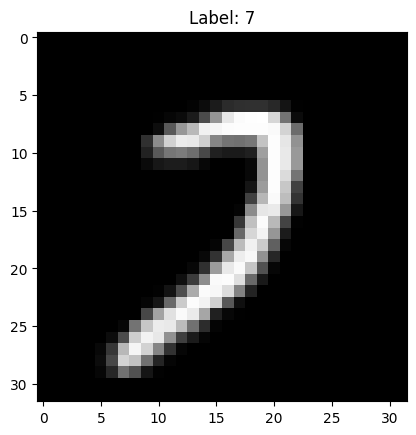

In [6]:
import matplotlib.pyplot as plt
image_index = 83
image, label = train_dataset[image_index]
plt.imshow(image[0], cmap='gray')
plt.title(f'Label: {label}')
plt.show()

**RUN & OBSERVE → EXPLAIN:** Compare the tensor shape with your prediction. Why is there only one channel?

**EXPERIMENT:** Change `image_index` and inspect another image.

## Investigation 2 — Understand a simple CNN architecture

The first convolution will use six learnable 5 × 5 filters, stride 1 and no padding. Each filter produces one feature map. ReLU acts elementwise. Average pooling replaces each 2 × 2 region with its average, with stride 2. We then flatten the feature maps and use a dense layer with 84 units followed by a ten-output layer.

For a spatial dimension $n$, kernel size $k$, padding $p$ and stride $s$, the output size is $\lfloor(n+2p-k)/s\rfloor+1$ (dilation 1).
Dilation controls the spacing between the elements of a convolutional kernel. A dilation of 1 corresponds to standard convolution, where the kernel operates on adjacent pixels. Larger dilation values increase the receptive field without increasing the number of trainable parameters.

**PREDICT:** Draw the architecture and calculate the channel count and spatial dimensions after convolution and pooling. Why does the first dense layer receive 1176 inputs? How many trainable parameters does the convolution have, including biases?

In [7]:
#Defining a class for our convolutional neural network
class SimpleCNN(nn.Module):
    def __init__(self, num_classes):
        super(SimpleCNN, self).__init__()
        torch.manual_seed(12345)
        #define the layers
        self.layer1 = nn.Sequential(   #Modules will be added to it in the order they are passed in the constructor.
            nn.Conv2d(1, 6, kernel_size=5, stride=1, padding=0), # Applies a 2D convolution with 1 channel in input (gray scale images); 6 channels in output, i.e. 6 different kernels;  Then controls kernel size, stride and padding (no padding applied here)
            nn.ReLU(), #activation function
            nn.AvgPool2d(kernel_size = 2, stride = 2)) #average pooling with specified size and stride
        self.fc = nn.Linear(1176, 84)  #Question: why 1176 nodes in input?
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(84, num_classes)

    #define the entire structure
    def forward(self, x):
        out = self.layer1(x)
        out = out.reshape(out.size(0), -1)
        out = self.fc(out)
        out = self.relu1(out)
        out = self.fc2(out)
        return out

The next cell passes a dummy batch through the layers without training. It prints the shapes and parameter count; the leading dimension is the batch size.

In [16]:
def model_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def inspect_shapes(model):
    model.eval()
    x = torch.zeros(batch_size, 1, 32, 32, device=device)
    print('Input:', tuple(x.shape))
    with torch.no_grad():
        for name, layer in model.named_children():
            if isinstance(layer, nn.Sequential):
                for j, operation in enumerate(layer):
                    x = operation(x)
                    print(f'{name}.{j} {type(operation).__name__}:', tuple(x.shape))
                    print('Trainable parameters:', model_params(operation))
            else:
                if isinstance(layer, nn.Linear) and x.ndim > 2:
                    x = x.flatten(1)
                    print('Flatten:', tuple(x.shape))
                x = layer(x)
                print(name, tuple(x.shape))
                print('Trainable parameters:', model_params(layer))
    print('Trainable parameters:', model_params(model))

model_simpleCNN = SimpleCNN(num_classes).to(device)
inspect_shapes(model_simpleCNN)

Input: (64, 1, 32, 32)
layer1.0 Conv2d: (64, 6, 28, 28)
Trainable parameters: 156
layer1.1 ReLU: (64, 6, 28, 28)
Trainable parameters: 0
layer1.2 AvgPool2d: (64, 6, 14, 14)
Trainable parameters: 0
Flatten: (64, 1176)
fc (64, 84)
Trainable parameters: 98868
relu1 (64, 84)
Trainable parameters: 0
fc2 (64, 10)
Trainable parameters: 850
Trainable parameters: 99874


**OBSERVE → EXPLAIN:** Compare the shapes with your calculations. Why does a convolution reuse the same weights across spatial positions? **EXPERIMENT:** Predict the average and maximum of a 2 × 2 patch $[[1, 2], [3, 8]]$ (see below code), then verify using the next cell. How does pooling affect the spatial dimensions of the input tensor? Do average pooling and max pooling produce different output shapes or just different numerical values?

In [17]:
patch = torch.tensor([[[[1., 2.], [3., 8.]]]])
print("Average:", nn.AvgPool2d(2)(patch))
print("Maximum:", nn.MaxPool2d(2)(patch))

Average: tensor([[[[3.5000]]]])
Maximum: tensor([[[[8.]]]])


## Investigation 3 — Understanding how we train a neural network

Before training our CNN, let us introduce the main ingredients of the learning procedure and understand how they are connected.

### A. From network outputs to class probabilities: logits and softmax

Our classification problem has ten possible classes, corresponding to the digits from 0 to 9.

For each input image, the network produces ten real-valued outputs:

$$
z=(z_0,z_1,\ldots,z_9).
$$

These values are called **logits**. They are scores associated with the different classes, not probabilities. They can be positive or negative, and their sum does not need to be equal to one.

To convert these scores into probabilities, we can apply the **softmax function**:

$$
p_k=\frac{\exp(z_k)}
{\sum_{j=0}^{9}\exp(z_j)},
\qquad k=0,\ldots,9.
$$

The resulting values satisfy

$$
p_k>0,\qquad \sum_{k=0}^{9}p_k=1.
$$

The predicted class is the class with the highest probability:

$$
\hat y=\arg\max_k p_k.
$$

Since softmax preserves the ordering of the logits, we can equivalently write

$$
\hat y=\arg\max_k z_k.
$$

Therefore, we do not need to compute softmax explicitly if we are only interested in the predicted class.

### B. Cross-entropy loss

Recall that, in supervised learning, we need a loss function to measure how well a model predicts the correct output.

In linear regression, we used the squared loss. In multiclass classification, a commonly used loss function is the **cross-entropy loss**.

Suppose that the true class of an image is $y$ and that the network assigns probabilities

$$
p=(p_0,p_1,\ldots,p_9)
$$

to the ten possible classes.

We can represent the true label using a one-hot vector $q$, where

$$
q_k=
\begin{cases}
1 & \text{if } k=y,\\
0 & \text{otherwise}.
\end{cases}
$$

The cross-entropy between the true label distribution $q$ and the predicted distribution $p$ is

$$
\ell(q,p)=-\sum_{k=0}^{9}q_k\log p_k.
$$

Since only the component corresponding to the correct class is equal to one, this expression simplifies to

$$
\boxed{\ell(y,p)=-\log p_y.}
$$

In other words, **the loss depends on the probability assigned by the network to the correct class**.

Let us consider a few examples:

| Probability assigned to the correct class | Cross-entropy loss |
|---|---:|
| 0.99 | 0.010 |
| 0.90 | 0.105 |
| 0.50 | 0.693 |
| 0.10 | 2.303 |
| 0.01 | 4.605 |

Notice that:

- If the network assigns a probability close to one to the correct class, the loss is close to zero.
- If the network assigns a low probability to the correct class, the loss is large.
- As the probability assigned to the correct class approaches zero, the loss tends to infinity.

Thus, cross-entropy strongly penalizes predictions that assign very low probability to the correct class.

**Why not simply minimize the classification error?**

The classification error only tells us whether the predicted class is correct or incorrect. It does not tell us how much probability the model assigns to the correct class.

Moreover, the classification error is not a suitable objective for ordinary gradient-based optimization: it is piecewise constant with respect to the network parameters.

Cross-entropy provides a differentiable loss with respect to the logits that allows us to use backpropagation and gradient-based optimization.

### C. From individual loss to empirical risk

Let $\theta$ denote all the trainable parameters of the neural network.

Given a training set of $m$ labelled images, the empirical risk associated with cross-entropy is

$$
L_{\mathcal S}(\theta)
=
-\frac{1}{m}
\sum_{i=1}^{m}
\log p_\theta(y_i\mid x_i).
$$

Training the network means searching for parameters $\theta$ that minimize this empirical risk.

This is the same learning principle that we studied in the previous labs: **Empirical Risk Minimization (ERM)**.

What changes is the hypothesis class, the loss function, and the optimization procedure.

### D. Cross-entropy in PyTorch

In PyTorch, we use

`cost = nn.CrossEntropyLoss()`

This function expects:

- the raw logits produced by the network;
- the correct class labels, represented as integer class indices.

It internally combines log-softmax and the negative log-likelihood of the correct class in a numerically stable way.

**Do not apply softmax to the network output before passing it to `CrossEntropyLoss`.**

For a mini-batch of 64 images, the network produces a tensor of shape `(64, 10)`, while the labels have shape `(64,)`.

By default, `CrossEntropyLoss` returns the average loss over the mini-batch.

### E. The optimization algorithm: Adam

In previous labs, we studied Gradient Descent (GD) and Stochastic Gradient Descent (SGD).

Here, we use **Adam (Adaptive Moment Estimation)**, another gradient-based optimization algorithm.

Adam maintains running estimates of the gradients and their squared values. It uses this information to adapt the updates of the individual parameters during training.

Like SGD, Adam uses gradients to update the parameters, but its update rule is more sophisticated.

For this lab, you do not need to know the mathematical details of Adam. You should understand its role: it uses the gradients of the loss to update the network parameters.

### F. Mini-batches and epochs

Instead of computing the gradient using the entire training set or a single example at every iteration, we process a small group of training examples at a time, called a **mini-batch**.

For each mini-batch, we compute the average loss, calculate its gradient, and perform one parameter update.

An **epoch** corresponds to one complete pass through the training set.

For example, with 50,000 training images and a batch size of 64, one epoch consists of approximately 782 mini-batch updates, including the final smaller batch.

### G. Understanding the training loop

For each mini-batch, the training loop performs the following operations:

**Forward pass — `outputs = model(images)`**

The images pass through the network, layer by layer, producing the logits.

**Loss computation — `loss = cost(outputs, labels)`**

We measure the discrepancy between the predictions and the correct labels using cross-entropy.


**Backpropagation — `loss.backward()`**

Using the chain rule, PyTorch computes the derivatives of the loss with respect to all trainable parameters.

**Parameter update — `optimizer.step()`**

Adam uses the computed gradients to update the weights and biases.

These operations are repeated for every mini-batch and for several epochs.

### H. Validation: evaluating without learning

After each epoch, we evaluate the network on the validation set.

During validation, we want to measure the performance of the current model without updating its parameters.

Two PyTorch instructions are particularly important:

- `model.eval()` switches the network to evaluation mode. Some layers, such as Batch Normalization and Dropout, behave differently during training and evaluation.
- `torch.no_grad()` disables gradient tracking, reducing memory consumption and unnecessary computations.

These two instructions have different purposes. Neither replaces the other.

After validation, `model.train()` switches the network back to training mode before the next training epoch.

The validation set is used to monitor generalization and select the best checkpoint. The test set remains separate and is used only for the final evaluation.

### J. Early stopping and checkpoint selection

Training for longer can reduce training loss without improving performance on unseen data. We use validation accuracy to choose the number of epochs, not test accuracy.

After each epoch, evaluate the current model on validation data. Whenever accuracy strictly improves, save an independent copy of its state (weights, biases and buffers, including batch-normalization statistics). At the end, restore the checkpoint with the highest validation accuracy; ties retain the earliest epoch.

In this lab we deliberately run all `max_epochs = 25` epochs so that we can inspect the complete learning curves. This is retrospective checkpoint selection, not an actual interruption of training. Early stopping uses the same idea but stops training once validation performance has failed to improve for a specified number of consecutive epochs (the **patience**). It then restores the best checkpoint, not the last one. For example, with patience 5, if the last improvement occurs at epoch 12 and epochs 13–17 do not improve, training stops after epoch 17 and restores epoch 12. This can save computation and act as a form of regularization, but noisy validation scores may cause premature stopping.

**PREDICT:** Must validation accuracy increase at every epoch? Will the best epoch necessarily be the last?

In [18]:
from copy import deepcopy

def evaluate(model, loader):
    model.eval()
    correct = total = 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            predicted = model(images).argmax(dim=1)
            correct += (predicted == labels).sum().item()
            total += labels.numel()
    return correct / total

def train_model(model, max_epochs, lr=learning_rate):
    train_loader.generator.manual_seed(SEED)
    cost = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    best_accuracy = -1.0
    history = {'loss': [], 'train_accuracy': [], 'val_accuracy': []}
    for epoch in range(1, max_epochs + 1):
        model.train()
        loss_sum = correct = total = 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            #At each iteration, we want to compute the gradient of the average loss over the current mini-batch.
            #Since PyTorch accumulates gradients by default,
            #we need to clear the previously stored gradients before calling loss.backward().
            optimizer.zero_grad()
            outputs = model(images)
            loss = cost(outputs, labels)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * labels.numel()
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.numel()
        val_accuracy = evaluate(model, validation_loader)
        history['loss'].append(loss_sum / total)
        history['train_accuracy'].append(correct / total)
        history['val_accuracy'].append(val_accuracy)
        print(f'Epoch {epoch}: loss={loss_sum/total:.4f}, validation accuracy={val_accuracy:.2%}')
        if val_accuracy > best_accuracy:
            best_accuracy, best_epoch = val_accuracy, epoch
            best_state = deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    model.eval()
    print(f'Selected epoch: {best_epoch}, validation accuracy: {best_accuracy:.2%}')
    return model, history, best_epoch

def plot_history(history):
    epochs = range(1, len(history['loss']) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    ax[0].plot(epochs, history['loss'], marker='o')
    ax[0].set(xlabel='Epoch', ylabel='Mean training loss')
    ax[1].plot(epochs, history['train_accuracy'], label='Training (during updates)')
    ax[1].plot(epochs, history['val_accuracy'], label='Validation')
    ax[1].set(xlabel='Epoch', ylabel='Accuracy')
    best_epoch = int(np.argmax(history['val_accuracy'])) + 1
    ax[1].axvline(best_epoch, linestyle='--', color='gray', label='Selected epoch')
    ax[1].legend()
    plt.tight_layout(); plt.show()

We now train a fresh SimpleCNN and plot the recorded loss and accuracies. Training accuracy here is accumulated during updates, not measured on a single fixed checkpoint.

Epoch 1: loss=0.2506, validation accuracy=96.62%
Epoch 2: loss=0.0872, validation accuracy=97.32%
Epoch 3: loss=0.0622, validation accuracy=97.78%
Epoch 4: loss=0.0515, validation accuracy=97.94%
Epoch 5: loss=0.0406, validation accuracy=97.86%
Epoch 6: loss=0.0342, validation accuracy=98.24%
Epoch 7: loss=0.0294, validation accuracy=97.88%
Epoch 8: loss=0.0244, validation accuracy=98.12%
Epoch 9: loss=0.0203, validation accuracy=98.53%
Epoch 10: loss=0.0182, validation accuracy=98.44%
Epoch 11: loss=0.0136, validation accuracy=98.29%
Epoch 12: loss=0.0147, validation accuracy=98.31%
Epoch 13: loss=0.0112, validation accuracy=98.46%
Epoch 14: loss=0.0098, validation accuracy=98.44%
Epoch 15: loss=0.0113, validation accuracy=98.42%
Epoch 16: loss=0.0070, validation accuracy=98.51%
Epoch 17: loss=0.0085, validation accuracy=98.50%
Epoch 18: loss=0.0069, validation accuracy=98.35%
Epoch 19: loss=0.0052, validation accuracy=98.35%
Epoch 20: loss=0.0069, validation accuracy=98.27%
Epoch 21:

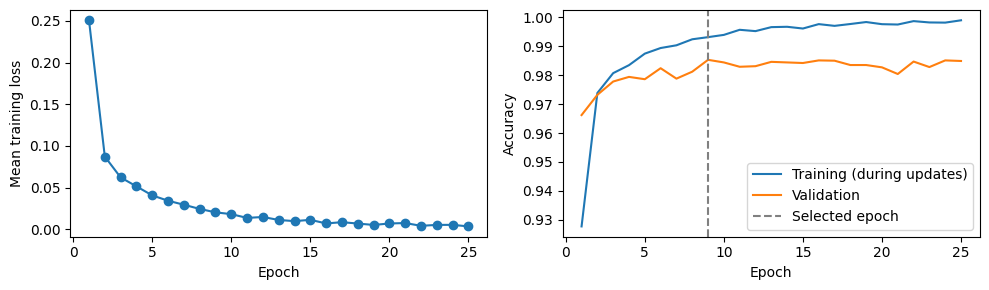

In [19]:
best_model_simpleCNN, history_CNN, best_num_epochs_CNN = train_model(SimpleCNN(num_classes).to(device), max_epochs)
plot_history(history_CNN)

**RUN & OBSERVE → EXPLAIN:** Which epoch was selected and why? Is the smallest training loss necessarily associated with the best validation accuracy?

**EXPERIMENT:** Use the recorded validation curve to simulate early stopping with patience 3. Predict the stopping epoch and the restored epoch before running the next cell. No additional training is needed.

In [20]:
def simulate_early_stopping(scores, patience):
    best = -float("inf")
    best_epoch = 0
    for epoch, score in enumerate(scores, 1):
        if score > best:
            best, best_epoch = score, epoch
        if epoch - best_epoch >= patience:
            return epoch, best_epoch
    return len(scores), best_epoch

for patience in (3, 6):
    stop, restore = simulate_early_stopping(history_CNN["val_accuracy"], patience)
    print(f"Patience {patience}: stop at {stop}, restore epoch {restore}")

Patience 3: stop at 12, restore epoch 9
Patience 6: stop at 15, restore epoch 9


## Investigation 4 — A LeNet-inspired CNN

In the previous investigation, we considered a relatively simple CNN with one convolutional layer followed by pooling and fully connected layers.

We now introduce a deeper architecture inspired by LeNet-5, one of the early convolutional neural networks designed for handwritten digit recognition.

### 1. Building a deeper CNN

Instead of applying a single convolution and pooling operation, we now use two consecutive convolutional blocks.

Each block consists of four operations:

- **Convolution:** extracts local features from the input.
- **Batch Normalization:** normalizes the activations of each channel.
- **ReLU:** introduces nonlinearity.
- **Average Pooling:** reduces the spatial dimensions of the feature maps.

The first convolutional layer receives a grayscale image with one input channel and produces six feature maps.

The second convolutional layer receives these six feature maps and produces sixteen new feature maps. Each filter in this second layer combines information from all six input channels.

This illustrates an important principle of CNNs: successive convolutional layers can learn increasingly complex representations by combining features extracted by previous layers.

As we move deeper into the network, the number of channels increases, while the spatial dimensions decrease.

### 2. Understanding Batch Normalization

Batch Normalization is a technique that can improve the stability and efficiency of neural network training by controlling the scale of intermediate activations.

Recall that in previous labs we standardized the input features before training a model. Batch Normalization applies a related idea, but **inside the neural network**, to the activations produced by intermediate layers.

During training, `BatchNorm2d` computes a mean and a variance for each channel, using all the images in the current mini-batch and all spatial positions within that channel.

For a given channel $c$, the normalization is

$$
\hat a_c =
\frac{a_c-\mu_c}{\sqrt{\sigma_c^2+\epsilon}},
$$

where:

- $\mu_c$ is the mean of the activations in channel $c$;
- $\sigma_c^2$ is their variance;
- $\epsilon$ is a small positive constant that ensures numerical stability.

The normalized activations are then transformed using two trainable parameters:

$$
a'_c=\gamma_c\hat a_c+\beta_c.
$$

The parameters $\gamma_c$ and $\beta_c$ allow the network to learn an appropriate scale and shift for each channel, rather than forcing the activations to always have zero mean and unit variance.

**How many trainable parameters does Batch Normalization introduce?**

For a layer with $C$ channels, Batch Normalization introduces $2C$ trainable parameters: one scale and one shift per channel.

It does not change the shape of the input tensor.

### 3. Batch Normalization during training and evaluation

During training, Batch Normalization uses the statistics of the current mini-batch. It also maintains running estimates of the mean and variance.

During validation and testing, it uses these stored running statistics instead of computing new statistics from the validation or test batch.

This is one reason why we must explicitly distinguish between training and evaluation modes in PyTorch:

- `model.train()` activates training behavior.
- `model.eval()` activates evaluation behavior.

The validation and test data must not contribute to the estimation of the running statistics.

Notice the connection with the preprocessing procedures studied in previous labs: information learned during training is used to process new observations.

### 4. From convolutional features to classification

After the two convolutional blocks, we flatten the resulting feature maps into a vector.

This vector is passed through three fully connected layers:

$$
400 \longrightarrow 120 \longrightarrow 84 \longrightarrow 10.
$$

The final ten outputs are the logits associated with the ten possible classes.

But where does the number 400 come from?

To answer this question, we need to follow the transformations of the input tensor through the entire architecture.

### PREDICT — Before running the code

Starting from an input image of shape $(1,32,32)$, calculate the output shape after each operation.

Recall that both convolutional layers use a $5\times5$ kernel, stride 1 and no padding, while both pooling layers use a $2\times2$ kernel and stride 2.

| Operation | Output shape |
|---|---|
| Input | $(1,32,32)$ |
| Convolution 1 | ? |
| Batch Normalization + ReLU | ? |
| Average Pooling 1 | ? |
| Convolution 2 | ? |
| Batch Normalization + ReLU | ? |
| Average Pooling 2 | ? |
| Flatten | ? |

Remember that the number of output channels is determined by the number of convolutional filters.

Discuss with your partner:

1. Why does the first fully connected layer receive exactly 400 inputs?
2. Which operations change the spatial dimensions?
3. Which operations introduce trainable parameters?
4. Do you expect this deeper network to have more trainable parameters than SimpleCNN? Why?

### RUN & OBSERVE

Run the following cells and compare the printed tensor shapes and parameter counts with your predictions.

### EXPLAIN

Does a deeper neural network necessarily have more trainable parameters?

Identify which layers contribute most to the total parameter count and explain the role of pooling in reducing the number of parameters required by the subsequent fully connected layers.

This is the architecture of LeNet5.

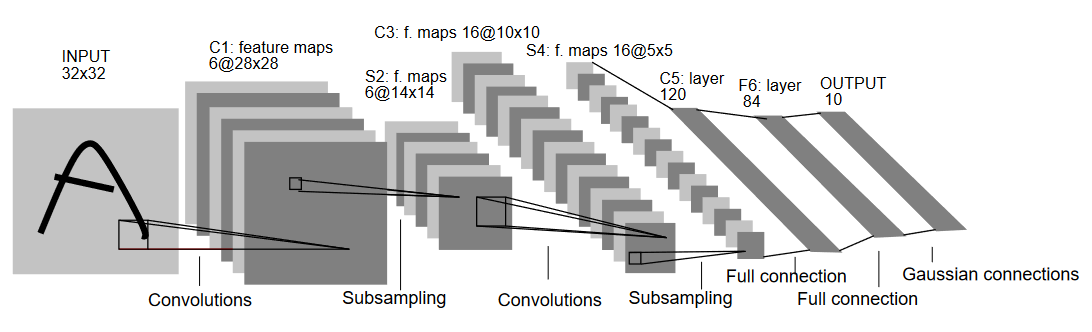

In [25]:
#Defining the convolutional neural network
class LeNet5(nn.Module):
    def __init__(self, num_classes):
        super(LeNet5, self).__init__()
        torch.manual_seed(2223755)
        self.layer1 = nn.Sequential(
            nn.Conv2d(1, 6, kernel_size=5, stride=1, padding=0),
            nn.BatchNorm2d(6),
            nn.ReLU(),
            nn.AvgPool2d(kernel_size = 2, stride = 2))
        self.layer2 = nn.Sequential(
            nn.Conv2d(6, 16, kernel_size=5, stride=1, padding=0),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.AvgPool2d(kernel_size = 2, stride = 2))
        self.fc = nn.Linear(400, 120)
        self.relu = nn.ReLU()
        self.fc1 = nn.Linear(120, 84)
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(84, num_classes)

    def forward(self, x):
        out = self.layer1(x)
        out = self.layer2(out)
        out = out.reshape(out.size(0), -1)
        out = self.fc(out)
        out = self.relu(out)
        out = self.fc1(out)
        out = self.relu1(out)
        out = self.fc2(out)
        return out

In [22]:
model = LeNet5(num_classes).to(device)
inspect_shapes(model)

Input: (64, 1, 32, 32)
layer1.0 Conv2d: (64, 6, 28, 28)
Trainable parameters: 156
layer1.1 BatchNorm2d: (64, 6, 28, 28)
Trainable parameters: 12
layer1.2 ReLU: (64, 6, 28, 28)
Trainable parameters: 0
layer1.3 AvgPool2d: (64, 6, 14, 14)
Trainable parameters: 0
layer2.0 Conv2d: (64, 16, 10, 10)
Trainable parameters: 2416
layer2.1 BatchNorm2d: (64, 16, 10, 10)
Trainable parameters: 32
layer2.2 ReLU: (64, 16, 10, 10)
Trainable parameters: 0
layer2.3 AvgPool2d: (64, 16, 5, 5)
Trainable parameters: 0
Flatten: (64, 400)
fc (64, 120)
Trainable parameters: 48120
relu (64, 120)
Trainable parameters: 0
fc1 (64, 84)
Trainable parameters: 10164
relu1 (64, 84)
Trainable parameters: 0
fc2 (64, 10)
Trainable parameters: 850
Trainable parameters: 61750


Train the LeNet variant using the same data, loss, optimizer, epoch budget 20 and validation-based checkpoint selection as before.

Epoch 1: loss=0.1850, validation accuracy=97.58%
Epoch 2: loss=0.0546, validation accuracy=98.11%
Epoch 3: loss=0.0419, validation accuracy=98.58%
Epoch 4: loss=0.0359, validation accuracy=98.57%
Epoch 5: loss=0.0298, validation accuracy=98.64%
Epoch 6: loss=0.0261, validation accuracy=98.84%
Epoch 7: loss=0.0239, validation accuracy=98.92%
Epoch 8: loss=0.0197, validation accuracy=98.92%
Epoch 9: loss=0.0178, validation accuracy=99.04%
Epoch 10: loss=0.0159, validation accuracy=98.29%
Epoch 11: loss=0.0141, validation accuracy=98.94%
Epoch 12: loss=0.0125, validation accuracy=99.02%
Epoch 13: loss=0.0122, validation accuracy=99.01%
Epoch 14: loss=0.0124, validation accuracy=99.08%
Epoch 15: loss=0.0108, validation accuracy=99.14%
Epoch 16: loss=0.0103, validation accuracy=98.90%
Epoch 17: loss=0.0078, validation accuracy=99.22%
Epoch 18: loss=0.0112, validation accuracy=99.12%
Epoch 19: loss=0.0071, validation accuracy=99.07%
Epoch 20: loss=0.0080, validation accuracy=98.80%
Epoch 21:

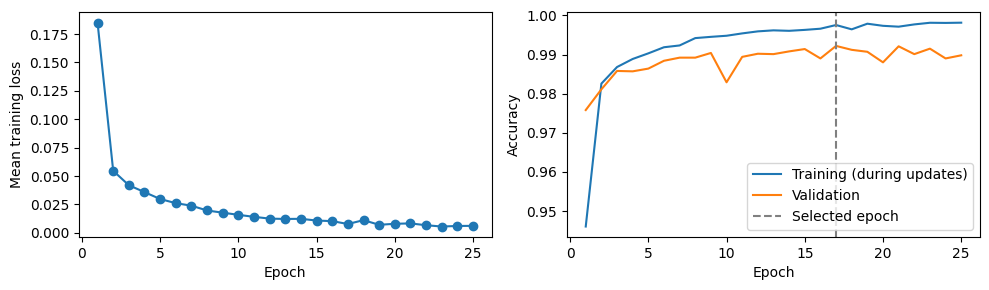

In [23]:
best_model_LeNet, history_LeNet, best_num_epochs_LeNet = train_model(model, max_epochs)
plot_history(history_LeNet)

**OBSERVE → EXPLAIN:** Compare the calculated shapes and parameter count with the output. Compare validation curves with SimpleCNN. Does a deeper network necessarily have more parameters? **EXPERIMENT:** Inspect the contribution of each layer to the total parameter count using the next cell.

In [24]:
for name, parameter in best_model_LeNet.named_parameters():
    print(name, tuple(parameter.shape), parameter.numel())

layer1.0.weight (6, 1, 5, 5) 150
layer1.0.bias (6,) 6
layer1.1.weight (6,) 6
layer1.1.bias (6,) 6
layer2.0.weight (16, 6, 5, 5) 2400
layer2.0.bias (16,) 16
layer2.1.weight (16,) 16
layer2.1.bias (16,) 16
fc.weight (120, 400) 48000
fc.bias (120,) 120
fc1.weight (84, 120) 10080
fc1.bias (84,) 84
fc2.weight (10, 84) 840
fc2.bias (10,) 10


## Investigation 5 — CNN versus fully connected network

The following NN flattens each image into 1024 pixel values, then uses a hidden layer with 60 ReLU units and ten output logits. Its parameter count is approximately comparable to the LeNet variant. Unlike convolution, dense connections do not explicitly exploit local neighborhoods or share filter weights across positions.

**PREDICT:** Calculate the number of parameters including biases. Which model do you expect to generalize better, and why? Does a similar parameter count imply the same hypothesis class?

In [26]:
#Defining a standard neural network
class NNstandard(nn.Module):
    def __init__(self, num_classes):
        super(NNstandard, self).__init__()
        self.fc1 = nn.Linear(1024, 60)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(60, num_classes)

    def forward(self, x):
        x = x.reshape(x.size(0), -1)
        out = self.fc1(x)
        out = self.relu(out)
        out = self.fc2(out)
        return out

Trainable parameters: 62110
Epoch 1: loss=0.3025, validation accuracy=94.53%
Epoch 2: loss=0.1524, validation accuracy=95.53%
Epoch 3: loss=0.1131, validation accuracy=96.56%
Epoch 4: loss=0.0932, validation accuracy=96.48%
Epoch 5: loss=0.0787, validation accuracy=96.88%
Epoch 6: loss=0.0667, validation accuracy=96.92%
Epoch 7: loss=0.0595, validation accuracy=97.18%
Epoch 8: loss=0.0525, validation accuracy=97.10%
Epoch 9: loss=0.0479, validation accuracy=97.26%
Epoch 10: loss=0.0430, validation accuracy=97.18%
Epoch 11: loss=0.0387, validation accuracy=97.05%
Epoch 12: loss=0.0351, validation accuracy=97.36%
Epoch 13: loss=0.0326, validation accuracy=97.35%
Epoch 14: loss=0.0297, validation accuracy=97.29%
Epoch 15: loss=0.0268, validation accuracy=97.20%
Epoch 16: loss=0.0263, validation accuracy=97.20%
Epoch 17: loss=0.0251, validation accuracy=97.59%
Epoch 18: loss=0.0222, validation accuracy=97.28%
Epoch 19: loss=0.0204, validation accuracy=97.41%
Epoch 20: loss=0.0199, validati

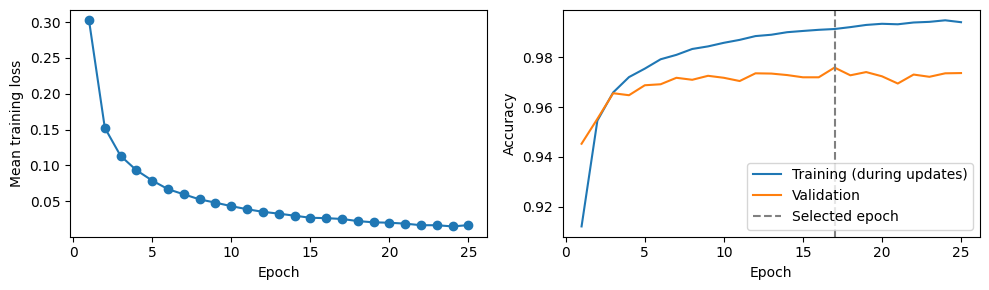

In [27]:
torch.manual_seed(SEED)
modelNN = NNstandard(num_classes).to(device)
print('Trainable parameters:', model_params(modelNN))
best_modelNN, history_NN, best_num_epochs_NN = train_model(modelNN, max_epochs)
plot_history(history_NN)

**RUN & OBSERVE → EXPLAIN:** Compare validation accuracy, parameter counts and the way each architecture processes images. What evidence supports your prediction? **EXPERIMENT:** Calculate how many parameters the dense network would have with 120 hidden units instead of 60. Compare with the actual model using the formula from Investigation 2.

## Investigation 6 — Linear classifier

This model maps the 1024 flattened pixels directly to ten logits. There is no hidden layer or nonlinear feature transformation. **PREDICT:** Calculate its parameter count and predict how its validation accuracy will compare with the other models. Run both cells below.

In [29]:
#Defining a linear model
class Linear(nn.Module):
    def __init__(self, num_classes):
        super(Linear, self).__init__()
        self.linear = nn.Linear(1024, num_classes)

    def forward(self, x):
        x = x.reshape(x.size(0), -1)
        out = self.linear(x)
        return out

Trainable parameters: 10250
Epoch 1: loss=0.3917, validation accuracy=91.39%
Epoch 2: loss=0.3029, validation accuracy=91.25%
Epoch 3: loss=0.2909, validation accuracy=91.73%
Epoch 4: loss=0.2864, validation accuracy=91.42%
Epoch 5: loss=0.2809, validation accuracy=90.99%
Epoch 6: loss=0.2779, validation accuracy=91.37%
Epoch 7: loss=0.2771, validation accuracy=91.71%
Epoch 8: loss=0.2737, validation accuracy=91.35%
Epoch 9: loss=0.2722, validation accuracy=91.16%
Epoch 10: loss=0.2711, validation accuracy=91.89%
Epoch 11: loss=0.2696, validation accuracy=91.98%
Epoch 12: loss=0.2676, validation accuracy=91.93%
Epoch 13: loss=0.2677, validation accuracy=91.54%
Epoch 14: loss=0.2659, validation accuracy=91.98%
Epoch 15: loss=0.2661, validation accuracy=92.02%
Epoch 16: loss=0.2641, validation accuracy=92.15%
Epoch 17: loss=0.2650, validation accuracy=92.18%
Epoch 18: loss=0.2645, validation accuracy=91.95%
Epoch 19: loss=0.2619, validation accuracy=91.89%
Epoch 20: loss=0.2609, validati

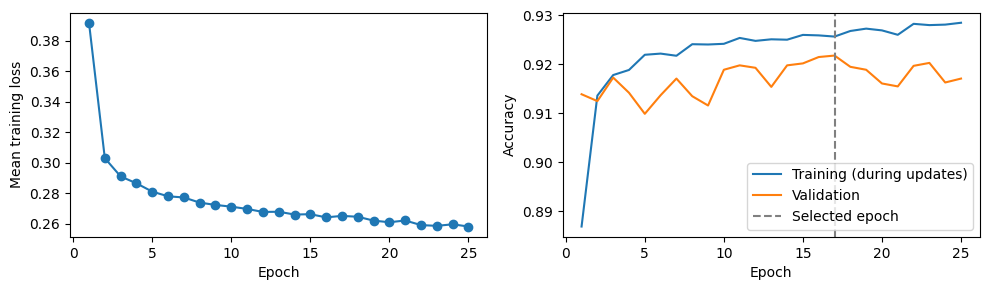

In [30]:
torch.manual_seed(SEED)
linear_model = Linear(num_classes).to(device)
print("Trainable parameters:", model_params(linear_model))
best_model_Linear, history_Linear, best_num_epochs_Linear = train_model(linear_model, max_epochs)
plot_history(history_Linear)

**RUN & OBSERVE → EXPLAIN:** Compare the linear model with the other three models using validation accuracy. **EXPERIMENT:** Compare their selected epochs and the gaps between training and validation accuracy. Does the simplest model necessarily generalize best?

## Final evaluation — Held-out test set

Before running the next cell, identify the model you would select based on validation results. We report all four models for comparison. We now evaluate the selected checkpoints on the same untouched test set. Higher accuracy is better; classification error is one minus accuracy. Do not return to architecture or epoch selection based on these test results.

**PREDICT:** Must the validation ranking match the test ranking? Why not?

In [31]:
import pandas as pd
models = [('SimpleCNN', best_model_simpleCNN, history_CNN, best_num_epochs_CNN),
          ('LeNet variant', best_model_LeNet, history_LeNet, best_num_epochs_LeNet),
          ('Dense NN', best_modelNN, history_NN, best_num_epochs_NN)]
models.append(('Linear', best_model_Linear, history_Linear, best_num_epochs_Linear))
results = pd.DataFrame([{'Model': name, 'Parameters': model_params(net), 'Selected epoch': epoch,
                         'Validation accuracy': hist['val_accuracy'][epoch-1],
                         'Test accuracy': evaluate(net, test_loader)}
                        for name, net, hist, epoch in models])
print(results.to_string(index=False))

        Model  Parameters  Selected epoch  Validation accuracy  Test accuracy
    SimpleCNN       99874               9               0.9853         0.9861
LeNet variant       61750              17               0.9922         0.9930
     Dense NN       62110              17               0.9759         0.9787
       Linear       10250              17               0.9218         0.9251


**OBSERVE → EXPLAIN:** Compare validation and test results. Can parameter count alone explain performance? What role does the architecture play?

## End-of-lab retrieval
Close the notebook and answer individually, then discuss with your partner:
- How do convolution, pooling and flattening change tensor dimensions?
- Why can a CNN generalize differently from a dense network with a similar number of parameters?
- What is the difference between an epoch and a mini-batch update?
- Why do we select checkpoints using validation rather than test data? How does early stopping differ from training for all 25 epochs and restoring the best checkpoint?

